In [28]:
pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


In [29]:
pip install -U scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [30]:
import pandas as pd

In [31]:
df = pd.read_csv(r'C:\Users\LENOVO\OneDrive - BUU\Meetings\Python\Medical Insurance Cost.csv')
print(df)

      age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]


In [32]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# -------------------------------------------------------------------------
# 0. ตั้งค่า path และโหลดข้อมูล
# -------------------------------------------------------------------------
# โฟลเดอร์หลักของโครงงาน
ROOT = Path(r"C:\Users\LENOVO\Downloads\Python")

# กำหนดที่อยู่ไฟล์ CSV
DATA = ROOT / "Medical Insurance Cost.csv"

TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
TAB.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# โหลดข้อมูลจากไฟล์ CSV
df = pd.read_csv(DATA)
print(f"โหลดข้อมูล {len(df)} แถว {df.shape[1]} คอลัมน์")
print(f"ค่าใช้จ่ายต่ำสุด-สูงสุด: {df['charges'].min():,.0f} - {df['charges'].max():,.0f}")

# -------------------------------------------------------------------------
# จัดกลุ่มข้อมูลและกำหนดลำดับตัวแปร
# -------------------------------------------------------------------------
# จัดกลุ่มภูมิภาค (Region)
TOP_REGIONS = ["southeast", "southwest", "northwest", "northeast"]
df["region_group"] = df["region"].where(df["region"].isin(TOP_REGIONS), "Other")

# เรียงลำดับหมวดหมู่ให้อ่านง่าย
ORDER_SEX = ["female", "male"]
ORDER_SMOKER = ["no", "yes"]
ORDER_REGION = ["southeast", "southwest", "northwest", "northeast"]

# จัดรูปแบบข้อความในคอลัมน์ให้อยู่ในรูปแบบมาตรฐาน (ตัวพิมพ์เล็ก ทั้งหมด)
key = df["region"].str.strip().str.lower()
canon = df.groupby(key)["region"].agg(lambda s: s.value_counts().index[0])
df["region_std"] = key.map(canon)

# ตั้งค่าธีมและสไตล์ของ กราฟ Matplotlib
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3
})

BLUE, ORANGE = "#2f6db5", "#e07b39"

def save(name):
    """บันทึกกราฟลง results/figures แล้วแสดงในโน้ตบุ๊ก"""
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150)
    plt.show()
    print("บันทึกกราฟ:", name)

โหลดข้อมูล 1338 แถว 7 คอลัมน์
ค่าใช้จ่ายต่ำสุด-สูงสุด: 1,122 - 63,770


In [33]:
# =========================================================================
# 1. สถิติเชิงพรรณนา (Descriptive Statistics)
# =========================================================================

# 1.1 ตัวแปรเชิงปริมาณ: จำนวน ค่าเฉลี่ย ส่วนเบี่ยงเบนมาตรฐาน ควอไทล์
num_cols = ["age", "bmi", "children", "charges"]
desc = df[num_cols].describe().T
desc["missing"] = df[num_cols].isna().sum()
desc = desc.round(1)
desc.to_csv(TAB / "descriptive_numeric.csv")

print("สถิติเชิงพรรณนา (ตัวแปรเชิงปริมาณ)")
display(desc)


# 1.2 ตัวแปรเชิงกลุ่ม: ความถี่และร้อยละ
cat_cols = ["sex", "smoker", "region_group"]
freq = []

for c in cat_cols:
    t = df[c].value_counts(dropna=False).rename_axis("category").reset_index(name="n")
    t["percent"] = (t["n"] / len(df) * 100).round(1)
    t.insert(0, "variable", c)
    freq.append(t)

freq = pd.concat(freq, ignore_index=True)
freq.to_csv(TAB / "frequency_categorical.csv", index=False)

print("\nความถี่ของตัวแปรเชิงกลุ่ม")
display(freq)

สถิติเชิงพรรณนา (ตัวแปรเชิงปริมาณ)


,count,mean,std,min,25%,50%,75%,max,missing
age,1338.0,39.2,14.0,18.0,27.0,39.0,51.0,64.0,0
bmi,1338.0,30.7,6.1,16.0,26.3,30.4,34.7,53.1,0
children,1338.0,1.1,1.2,0.0,0.0,1.0,2.0,5.0,0
charges,1338.0,13270.4,12110.0,1121.9,4740.3,9382.0,16639.9,63770.4,0



ความถี่ของตัวแปรเชิงกลุ่ม


,variable,category,n,percent
0,sex,male,676,50.5
1,sex,female,662,49.5
2,smoker,no,1064,79.5
3,smoker,yes,274,20.5
4,region_group,southeast,364,27.2
5,region_group,southwest,325,24.3
6,region_group,northwest,325,24.3
7,region_group,northeast,324,24.2


In [34]:
# =========================================================================
# 1.3 ค่าใช้จ่ายประกันสุขภาพแยกตามกลุ่ม: n, ค่าเฉลี่ย, มัธยฐาน, SD, Q1, Q3
# =========================================================================

def charges_by(col, order=None):
    g = df.groupby(col)["charges"]
    out = pd.DataFrame({
        "n": g.size(), 
        "mean": g.mean(), 
        "median": g.median(), 
        "sd": g.std(),
        "q1": g.quantile(0.25), 
        "q3": g.quantile(0.75)
    }).round(1)
    if order:
        out = out.reindex([o for o in order if o in out.index])
    return out

# กำหนดตารางการจัดกลุ่มตามตัวแปรเชิงกลุ่มต่างๆ ในชุดข้อมูล
group_tables = {
    "sex": charges_by("sex", ORDER_SEX),
    "smoker": charges_by("smoker", ORDER_SMOKER),
    "region_group": charges_by("region_group", ORDER_REGION),
}

# บันทึกเป็นไฟล์ CSV และแสดงผลตาราง
for name, t in group_tables.items():
    t.to_csv(TAB / f"charges_by_{name}.csv")
    print(f"--- ค่าใช้จ่ายประกันสุขภาพแยกตาม {name} ---")
    display(t)
    print()

--- ค่าใช้จ่ายประกันสุขภาพแยกตาม sex ---


,n,mean,median,sd,q1,q3
sex,,,,,,
female,662,12569.6,9413.0,11128.7,4885.2,14454.7
male,676,13956.8,9369.6,12971.0,4619.1,18989.6



--- ค่าใช้จ่ายประกันสุขภาพแยกตาม smoker ---


,n,mean,median,sd,q1,q3
smoker,,,,,,
no,1064,8434.3,7345.4,5993.8,3986.4,11362.9
yes,274,32050.2,34456.3,11541.5,20826.2,41019.2



--- ค่าใช้จ่ายประกันสุขภาพแยกตาม region_group ---


,n,mean,median,sd,q1,q3
region_group,,,,,,
southeast,364,14735.4,9294.1,13971.1,4440.9,19526.3
southwest,325,12346.9,8798.6,11557.2,4751.1,13462.5
northwest,325,12417.6,8965.8,11072.3,4719.7,14711.7
northeast,324,13406.4,10057.7,11255.8,5194.3,16687.4


In [35]:
# 1.1 คำนวณสถิติข้อที่ 1
# กรองข้อมูล: เพศหญิง (sex == 'female') และ สูบบุหรี่ (smoker == 'yes')
df_q1 = df[(df["sex"] == "female") & (df["smoker"] == "yes")]

# คำนวณค่าเฉลี่ย ผลรวม และจำนวนคน แยกตามจำนวนบุตร (children)
stats_q1 = df_q1.groupby("children")["charges"].agg(
    n="count",
    mean_charges="mean",
    sum_charges="sum"
).round(2).reset_index()

# บันทึกตารางสถิติลงไฟล์
stats_q1.to_csv(TAB / "q1_female_smoker_charges_by_children.csv", index=False)

print("=== สถิติข้อที่ 1: ค่าเบี้ยประกันของกลุ่มผู้หญิงที่สูบบุหรี่ แยกตามจำนวนบุตร ===")
display(stats_q1)

=== สถิติข้อที่ 1: ค่าเบี้ยประกันของกลุ่มผู้หญิงที่สูบบุหรี่ แยกตามจำนวนบุตร ===


,children,n,mean_charges,sum_charges
0,0,53,30685.06,1626308.17
1,1,25,30264.25,756606.35
2,2,22,31663.83,696604.33
3,3,14,30681.60,429542.46
4,5,1,19023.26,19023.26


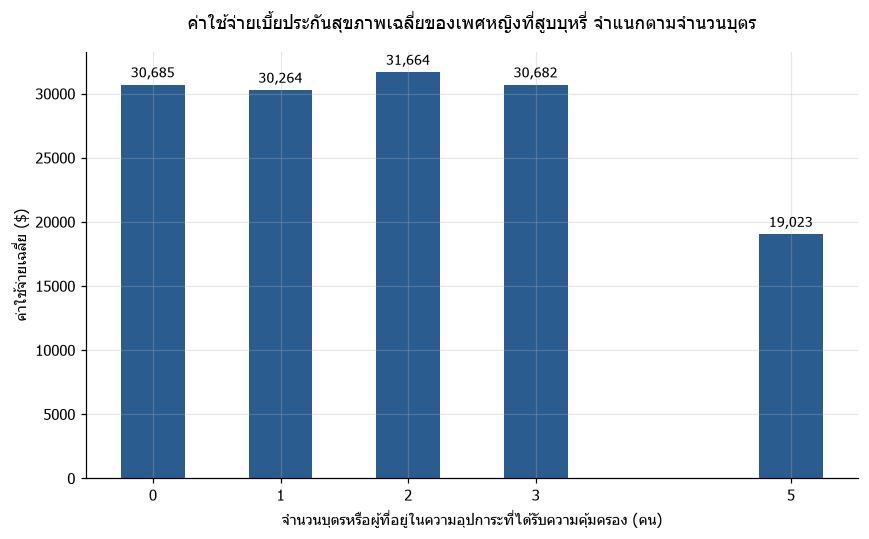

In [36]:
# 1.2 สร้างกราฟแท่งข้อที่ 1
import matplotlib.pyplot as plt

# ตั้งค่าให้ Matplotlib รองรับภาษาไทย (ป้องกันตัวหนังสือเป็นสี่เหลี่ยมและ Warning)
plt.rcParams['font.family'] = 'Tahoma'
plt.rcParams['axes.unicode_minus'] = False

# กำหนดสีสำหรับกราฟ
BLUE = "#2b5c8f"

# สร้างกราฟแท่ง
fig, ax = plt.subplots(figsize=(8, 5))

x = stats_q1["children"]
y = stats_q1["mean_charges"]

bars = ax.bar(x, y, color=BLUE, width=0.5)

# ใส่ตัวเลขแสดงค่าเฉลี่ยกำกับบนหัวแท่งกราฟ
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:,.0f}",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha="center", va="bottom", fontsize=9)

# กำหนดชื่อกราฟและป้ายชื่อแกนเป็นภาษาไทย
ax.set_title("ค่าใช้จ่ายเบี้ยประกันสุขภาพเฉลี่ยของเพศหญิงที่สูบบุหรี่ จำแนกตามจำนวนบุตร", fontsize=12, pad=15)
ax.set_xlabel("จํานวนบุตรหรือผู้ที่อยู่ในความอุปการะที่ได้รับความคุ้มครอง (คน)")
ax.set_ylabel("ค่าใช้จ่ายเฉลี่ย ($)")
ax.set_xticks(x)

# บันทึกรูปภาพ
plt.tight_layout()
plt.savefig("q1_female_smoker_charges_by_children.png", dpi=300)
plt.show()

In [37]:
# 2.1 คำนวณสถิติข้อที่ 2
# กรองข้อมูล: ผู้สูบบุหรี่ (smoker == 'yes')
df_q2 = df[df["smoker"] == "yes"]

# คำนวณสถิติตามภูมิภาคและเพศ
stats_q2 = df_q2.groupby(["region", "sex"])["charges"].agg(
    n="count",
    median="median",
    q1=lambda x: x.quantile(0.25),
    q3=lambda x: x.quantile(0.75),
    min="min",
    max="max"
).reset_index()

# คำนวณหา IQR และขอบเขตเพื่อตรวจจับค่าผิดปกติ (Outliers)
stats_q2["iqr"] = stats_q2["q3"] - stats_q2["q1"]
stats_q2["lower_bound"] = stats_q2["q1"] - 1.5 * stats_q2["iqr"]
stats_q2["upper_bound"] = stats_q2["q3"] + 1.5 * stats_q2["iqr"]
stats_q2 = stats_q2.round(2)

# บันทึกตารางสถิติ
stats_q2.to_csv(TAB / "q2_smoker_charges_by_region_sex.csv", index=False)

print("=== สถิติข้อที่ 2: การกระจายตัวของค่าเบี้ยประกันกลุ่มผู้สูบบุหรี่ (แยกตามภูมิภาคและเพศ) ===")
display(stats_q2)

=== สถิติข้อที่ 2: การกระจายตัวของค่าเบี้ยประกันกลุ่มผู้สูบบุหรี่ (แยกตามภูมิภาคและเพศ) ===


,region,sex,n,median,q1,q3,min,max,iqr,lower_bound,upper_bound
0,northeast,female,29,22331.57,16776.30,38511.63,14283.46,58571.07,21735.32,-15826.68,71114.61
1,northeast,male,38,33993.37,21052.91,39587.18,12829.46,48549.18,18534.26,-6748.48,67388.58
2,northwest,female,29,28950.47,21348.71,39725.52,14711.74,55135.40,18376.81,-6216.51,67290.74
3,northwest,male,29,26109.33,20745.99,40720.55,15817.99,60021.40,19974.56,-9215.85,70682.39
4,southeast,female,36,35017.72,23199.95,41473.09,16577.78,63770.43,18273.14,-4209.76,68882.80
5,southeast,male,55,38282.75,24572.31,44008.26,17043.34,62592.87,19435.95,-4581.60,73162.18
6,southwest,female,21,34166.27,19023.26,41661.60,13844.51,48824.45,22638.34,-14934.25,75619.11
7,southwest,male,37,35585.58,22144.03,39241.44,15820.70,52590.83,17097.41,-3502.08,64887.56


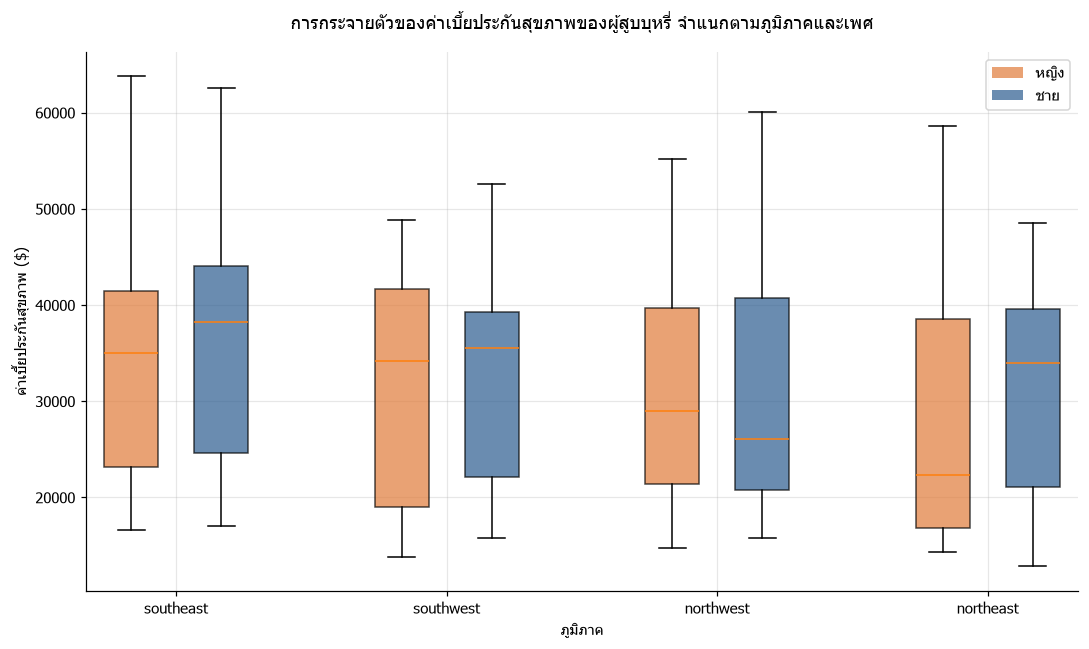

บันทึกกราฟ: q2_smoker_charges_boxplot_region_sex.png


In [38]:
# 2.2 สร้างแผนภาพกล่องข้อที่ 2
regions = ORDER_REGION
sexes = ["female", "male"]

# จัดเตรียมข้อมูลในรูป List สำหรับวาด Boxplot คู่กัน
data_to_plot = []
positions = []
labels = []

pos = 1
for reg in regions:
    for sex in sexes:
        subset = df_q2[(df_q2["region"] == reg) & (df_q2["sex"] == sex)]["charges"]
        data_to_plot.append(subset)
        positions.append(pos)
        pos += 1
    pos += 1  # เว้นระยะห่างระหว่างภูมิภาค

fig, ax = plt.subplots(figsize=(10, 6))

# วาด Boxplot
bp = ax.boxplot(data_to_plot, positions=positions, patch_artist=True, widths=0.6)

# ใส่สีแยกตามเพศ (หญิง = ส้ม, ชาย = น้ำเงิน)
colors = [ORANGE, BLUE] * len(regions)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# กำหนดชื่อแกนและ X-ticks
tick_pos = [i * 3 + 1.5 for i in range(len(regions))]
ax.set_xticks(tick_pos)
ax.set_xticklabels(regions)

# ทำ Custom Legend อธิบายสี (แปลภาษาไทย)
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=ORANGE, alpha=0.7, label='หญิง'),
    Patch(facecolor=BLUE, alpha=0.7, label='ชาย')
]
ax.legend(handles=legend_elements, loc='upper right')

# ชื่อหัวข้อและแกนภาษาไทย
ax.set_title("การกระจายตัวของค่าเบี้ยประกันสุขภาพของผู้สูบบุหรี่ จำแนกตามภูมิภาคและเพศ", fontsize=12, pad=15)
ax.set_xlabel("ภูมิภาค")
ax.set_ylabel("ค่าเบี้ยประกันสุขภาพ ($)")

save("q2_smoker_charges_boxplot_region_sex.png")

In [39]:
# 3.1 คำนวณสถิติข้อที่ 3
from scipy import stats

# กรองข้อมูล: เพศชาย (sex == 'male') และ สูบบุหรี่ (smoker == 'yes')
df_q3 = df[(df["sex"] == "male") & (df["smoker"] == "yes")].dropna(subset=["age", "charges"])

# คำนวณค่าสัมประสิทธิ์สหสัมพันธ์ (Pearson & Spearman Correlation)
r_pearson, p_pearson = stats.pearsonr(df_q3["age"], df_q3["charges"])
r_spearman, p_spearman = stats.spearmanr(df_q3["age"], df_q3["charges"])

corr_summary = pd.DataFrame({
    "Metric": ["Pearson Correlation (r)", "Spearman Correlation (rho)"],
    "Value": [round(r_pearson, 4), round(r_spearman, 4)],
    "p-value": [p_pearson, p_spearman]
})

# บันทึกผลคำนวณ
corr_summary.to_csv(TAB / "q3_male_smoker_age_charges_correlation.csv", index=False)

print("=== สถิติข้อที่ 3: สัมประสิทธิ์สหสัมพันธ์ระหว่างอายุกับเบี้ยประกัน (ผู้ชายที่สูบบุหรี่) ===")
display(corr_summary)

=== สถิติข้อที่ 3: สัมประสิทธิ์สหสัมพันธ์ระหว่างอายุกับเบี้ยประกัน (ผู้ชายที่สูบบุหรี่) ===


,Metric,Value,p-value
0,Pearson Correlation (r),0.3792,8.285838e-07
1,Spearman Correlation (rho),0.4727,3.161439e-10


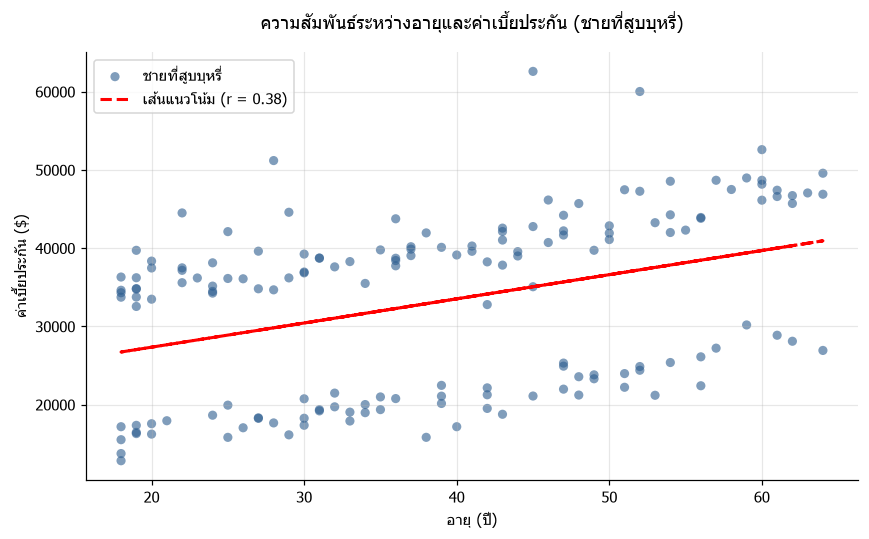

บันทึกกราฟ: q3_male_smoker_age_vs_charges_scatterplot.png


In [40]:
# 3.2 สร้างกราฟ Scatter Plot ข้อที่ 3
fig, ax = plt.subplots(figsize=(8, 5))

x = df_q3["age"]
y = df_q3["charges"]

# วาดจุด Scatter (แปล label เป็นภาษาไทย)
ax.scatter(x, y, color=BLUE, alpha=0.6, edgecolors="none", label="ชายที่สูบบุหรี่")

# คำนวณและวาดเส้นแนวโน้มเชิงเส้น (Regression Line)
m, b = np.polyfit(x, y, 1)
ax.plot(x, m * x + b, color="red", linestyle="--", linewidth=2, label=f"เส้นแนวโน้ม (r = {r_pearson:.2f})")

# กำหนดชื่อหัวข้อและชื่อแกนเป็นภาษาไทย
ax.set_title("ความสัมพันธ์ระหว่างอายุและค่าเบี้ยประกัน (ชายที่สูบบุหรี่)", fontsize=12, pad=15)
ax.set_xlabel("อายุ (ปี)")
ax.set_ylabel("ค่าเบี้ยประกัน ($)")

# ย้ายกล่องคำอธิบายไปไว้ทางด้านซ้าย (มุมบนซ้าย)
ax.legend(loc="upper left")

save("q3_male_smoker_age_vs_charges_scatterplot.png")